# Búsqueda de empleo sin experiencia
### Informe final del proyecto de Minería de Datos

Bryan Samuel Vélez Velásquez y Jhon Jairo Melo Largo<br>
Docente: Paola Andrea Ortiz<br>
CIAF, noviembre de 2026

Repositorio: https://github.com/samuelvelez1003/Busqueda-Empleo

---
## 1. Resumen ejecutivo

**El problema.** Muchos jóvenes en Colombia terminan el colegio o una carrera y no consiguen su primer empleo porque no tienen experiencia. Quien los orienta (el servicio de empleo, una institución educativa o una alcaldía) necesita saber qué formación recomendarles y hacia qué regiones orientarlos.

**La pregunta.** ¿Qué características de los jóvenes de 18 a 28 años sin experiencia laboral (edad, sexo, nivel educativo, si estudian y dónde viven) se asocian con conseguir su primer empleo, y cómo se relacionan con la demanda de vacantes de su departamento?

**La hipótesis con la que empezamos.** Que la formación técnica o tecnológica ayuda a conseguir el primer empleo, porque las vacantes de entrada valoran más lo práctico que un título universitario.

**Los datos.** Usamos dos fuentes públicas y las cruzamos por departamento:

- La **GEIH 2025 del DANE** (Gran Encuesta Integrada de Hogares, enero a diciembre). Tiene, persona por persona, la edad, el sexo, los estudios, si trabaja o busca trabajo, si ha trabajado antes, el ingreso y si cotiza a pensión. De ahí salen 41.784 jóvenes sin experiencia en la muestra, que representan a unos 2,85 millones.
- Las **vacantes del Servicio Público de Empleo (SPE) de 2023**, que es el último año publicado. Por departamento dice cuántas vacantes no piden experiencia y qué nivel educativo piden.

Tomamos como "sin experiencia" a dos grupos: los aspirantes (buscan trabajo y nunca han trabajado) y los recién insertados (consiguieron su primer empleo en los últimos 12 meses). Lo que estudiamos es si el joven ya consiguió ese primer empleo o no.

**Lo que encontramos, en corto:**

- La hipótesis no se cumple para *conseguir* empleo, pero sí para que el empleo sea *bueno*. Los que menos estudiaron entran más rápido (96 % con básica contra 89 % de técnicos y universitarios), pero a trabajos informales. Con formación técnica o tecnológica la formalidad del primer empleo pasa de 38 % (bachiller) a 62-67 %.
- El departamento pesa tanto como los estudios. Encontramos 3 tipos: donde se entra con empleo formal (15), donde cuesta entrar (8, sobre todo el Caribe y Chocó) y donde se entra pero a la informalidad (10, en el sur y el Caribe interior).
- Con edad, estudios y departamento no se puede predecir bien quién se va a quedar sin empleo. El mejor modelo encuentra 7 de cada 10 aspirantes, pero da casi 5 alertas falsas por cada acierto. Sirve para priorizar, no para decidir.
- Para muchos el primer empleo es un rebusque: entre los primeros empleos más raros que encontramos, la mayoría son trabajos por cuenta propia de menos de $500.000 al mes.

In [1]:
import os, sys
if "google.colab" in sys.modules and not os.path.isdir("../data/raw"):
    if not os.path.isdir("/content/Busqueda-Empleo"):
        !git clone https://github.com/samuelvelez1003/Busqueda-Empleo.git /content/Busqueda-Empleo
    %cd /content/Busqueda-Empleo/notebooks

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from preparacion import preparar_datos

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 10})

DATA_DIR = "../data" if os.path.isdir("../data") else "data"
SALIDA = os.path.join(DATA_DIR, "processed")
X, y, pesos, datos, pipeline = preparar_datos(os.path.join(SALIDA, "dataset_cruzado_sin_experiencia.csv"))

# Resultados guardados por el notebook 04 (Checkpoint 2)
segmentos = pd.read_csv(os.path.join(SALIDA, "segmentos_departamentos.csv"))
modelos = pd.read_csv(os.path.join(SALIDA, "comparacion_modelos.csv"), index_col=0)
importancia = pd.read_csv(os.path.join(SALIDA, "importancia_variables_modelo.csv"), index_col=0)["importancia"]
anomalias = pd.read_csv(os.path.join(SALIDA, "anomalias_primer_empleo.csv"))

def tasa(g, columna="consiguio_empleo"):
    g = g[g[columna].notna()]
    return np.average(g[columna].astype(float), weights=g["factor_expansion"]) * 100

---
## 2. Producto analítico: lo que encontramos

### Algunas cifras generales

In [2]:
insertados = datos[datos["consiguio_empleo"] == 1]
cifras = {
    "Jóvenes sin experiencia representados": f"{datos['factor_expansion'].sum():,.0f}".replace(",", "."),
    "Consiguieron su primer empleo (últimos 12 meses)": f"{tasa(datos):.1f} %".replace(".", ","),
    "Siguen buscando sin haber trabajado nunca": f"{datos.loc[datos['consiguio_empleo'] == 0, 'factor_expansion'].sum():,.0f}".replace(",", "."),
    "Primer empleo formal (cotiza a pensión)": f"{tasa(insertados, 'empleo_formal'):.1f} %".replace(".", ","),
    "Departamentos analizados": f"{datos['departamento'].nunique()}",
}
pd.Series(cifras, name="").to_frame()

,
Jóvenes sin experiencia representados,2.846.816
Consiguieron su primer empleo (últimos 12 meses),"91,9 %"
Siguen buscando sin haber trabajado nunca,231.971
Primer empleo formal (cotiza a pensión),"44,5 %"
Departamentos analizados,33


### Hallazgo 1. Estudiar más no ayuda a entrar más rápido, pero sí a entrar mejor

Esto sale del EDA del Checkpoint 1, con una corrección que hicimos después de las anomalías del Checkpoint 2.

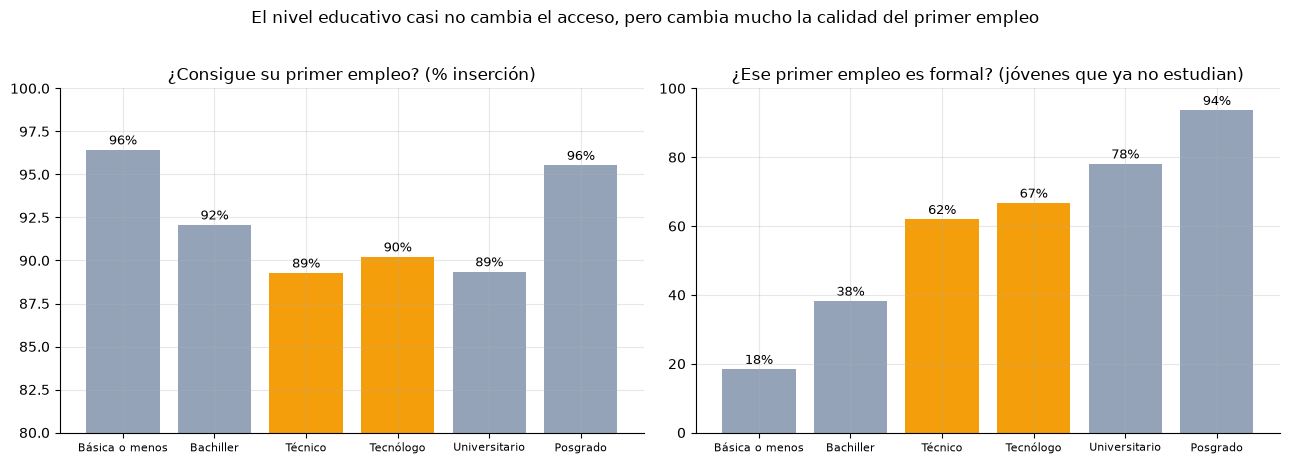

,inserción_%,formalidad_%,formalidad_%_ya_no_estudia,%_que_aún_estudia
Básica o menos,96.4,18.4,18.4,2.4
Bachiller,92.1,37.7,38.3,2.1
Técnico,89.3,58.5,62.0,16.1
Tecnólogo,90.2,62.2,66.7,25.6
Universitario,89.4,66.0,78.1,47.1
Posgrado,95.5,91.3,93.7,46.7


In [3]:
orden = ["Básica o menos", "Bachiller", "Técnico", "Tecnólogo", "Universitario", "Posgrado"]
no_estudia = datos[datos["estudia_actualmente"] == False]
ins_no_estudia = no_estudia[no_estudia["consiguio_empleo"] == 1]

tabla_edu = pd.DataFrame({
    "inserción_%": [tasa(datos[datos["nivel_educativo_grupo"] == n]) for n in orden],
    "formalidad_%": [tasa(insertados[insertados["nivel_educativo_grupo"] == n], "empleo_formal") for n in orden],
    "formalidad_%_ya_no_estudia": [tasa(ins_no_estudia[ins_no_estudia["nivel_educativo_grupo"] == n], "empleo_formal") for n in orden],
    "%_que_aún_estudia": [tasa(datos[datos["nivel_educativo_grupo"] == n], "estudia_actualmente") for n in orden],
}, index=orden)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
colores = ["#f59e0b" if n in ("Técnico", "Tecnólogo") else "#94a3b8" for n in orden]
ax[0].bar(orden, tabla_edu["inserción_%"], color=colores)
ax[0].set_ylim(80, 100)
ax[0].set_title("¿Consigue su primer empleo? (% inserción)")
for i, v in enumerate(tabla_edu["inserción_%"]):
    ax[0].text(i, v + .3, f"{v:.0f}%", ha="center", fontsize=9)
ax[1].bar(orden, tabla_edu["formalidad_%_ya_no_estudia"], color=colores)
ax[1].set_ylim(0, 100)
ax[1].set_title("¿Ese primer empleo es formal? (jóvenes que ya no estudian)")
for i, v in enumerate(tabla_edu["formalidad_%_ya_no_estudia"]):
    ax[1].text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9)
for a in ax:
    a.tick_params(axis="x", labelsize=8)
plt.suptitle("El nivel educativo casi no cambia el acceso, pero cambia mucho la calidad del primer empleo", y=1.02)
plt.tight_layout()
plt.show()
tabla_edu.round(1)

En la gráfica de la izquierda se ve que los que tienen básica o menos son los que más consiguen empleo (96 %), por encima de técnicos, tecnólogos y universitarios (89-90 %). Nuestra explicación es que el que estudió menos acepta lo primero que le salga, y el que estudió más espera algo acorde. Así que la hipótesis inicial no se cumple para el acceso.

La de la derecha muestra la otra cara: entre los que ya no estudian, la formalidad del primer empleo sube de 18 % (básica) y 38 % (bachiller) a 62 % (técnico), 67 % (tecnólogo), 78 % (universitario) y 94 % (posgrado).

Aquí corregimos algo del Checkpoint 1. Ahí dijimos que técnicos, tecnólogos y universitarios tenían una formalidad parecida (59 %, 62 % y 66 %). Pero en las anomalías nos dimos cuenta de que el 47 % de los "universitarios" todavía están estudiando, porque la GEIH cuenta como universitario al que está cursando, y sus trabajos de estudiante bajaban el promedio. Si se separan, el universitario sí tiene más empleo formal que el técnico (78 % contra 62 %).

Para la recomendación: al que necesita trabajar pronto le conviene la formación técnica o tecnológica, porque en 2 o 3 años pasa de 38 % a 62-67 % de formalidad. La universidad completa da el empleo más formal, pero son 5 años.

### Hallazgo 2. El departamento pesa tanto como los estudios

Esto sale de la segmentación del Checkpoint 2 (sección 1).

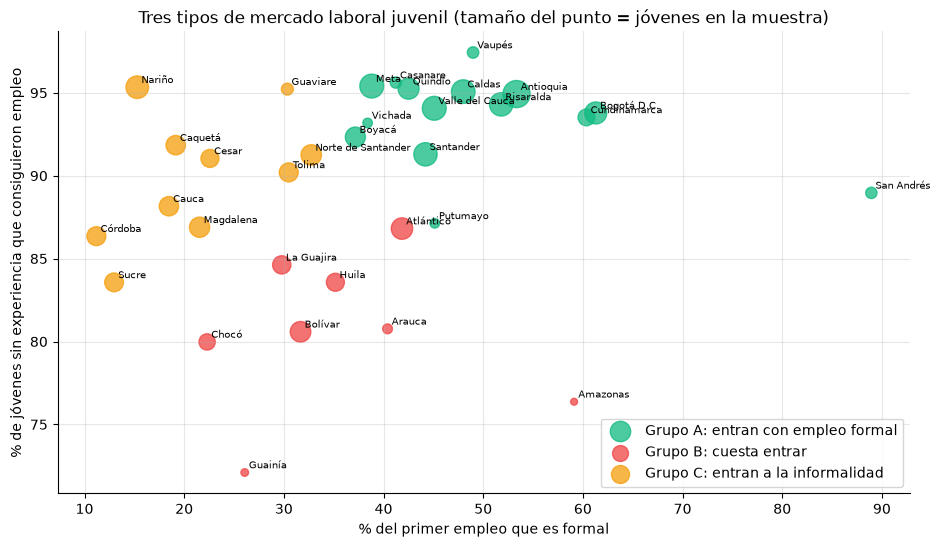

,departamentos,inserción_promedio,formalidad_promedio,ejemplos
segmento,,,,
Grupo A: entran con empleo formal,15,93.5,49.7,"Antioquia, Bogotá D.C., Boyacá, Caldas, Cundin..."
Grupo B: cuesta entrar,8,80.6,35.8,"Atlántico, Bolívar, Chocó, Huila, La Guajira"
Grupo C: entran a la informalidad,10,90.0,21.5,"Caquetá, Cauca, Cesar, Córdoba, Magdalena"


In [4]:
COLORES_SEG = {"Grupo A: entran con empleo formal": "#10b981", "Grupo B: cuesta entrar": "#ef4444",
               "Grupo C: entran a la informalidad": "#f59e0b"}
fig, ax = plt.subplots(figsize=(11, 6))
for seg, g in segmentos.groupby("segmento"):
    ax.scatter(g["pct_formal"], g["tasa_insercion"], s=g["n_muestra"] / 8 + 20, alpha=.75,
               color=COLORES_SEG[seg], label=seg)
for _, r in segmentos.iterrows():
    ax.annotate(r["departamento"], (r["pct_formal"], r["tasa_insercion"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("% del primer empleo que es formal")
ax.set_ylabel("% de jóvenes sin experiencia que consiguieron empleo")
ax.set_title("Tres tipos de mercado laboral juvenil (tamaño del punto = jóvenes en la muestra)")
ax.legend(loc="lower right")
plt.show()

resumen_seg = segmentos.groupby("segmento").agg(
    departamentos=("departamento", "count"),
    inserción_promedio=("tasa_insercion", "mean"),
    formalidad_promedio=("pct_formal", "mean"),
    ejemplos=("departamento", lambda s: ", ".join(s.head(5))),
).round(1)
resumen_seg

- **Grupo A, entran con empleo formal** (15 departamentos: Bogotá, Antioquia, Valle, el Eje Cafetero, Santander y parte de los Llanos). Entra el 93,5 % y la mitad con empleo formal. Es hacia donde convendría orientar a quien se pueda mover.
- **Grupo B, cuesta entrar** (8: Atlántico, Bolívar, La Guajira, Chocó, Huila, Arauca, entre otros). 1 de cada 5 jóvenes que busca no ha conseguido su primer empleo. Aquí hacen falta programas de primer empleo, como prácticas y contrato de aprendizaje.
- **Grupo C, entran a la informalidad** (10: Nariño, Cauca, Córdoba, Sucre, Magdalena, entre otros). Entra el 90 %, pero casi 4 de cada 5 sin cotizar a pensión. Aquí lo que hace falta es formación técnica que lleve a empleos formales.

Hay que tener cuidado con Amazonas y Guainía: quedaron en el grupo B, pero tienen muy pocos encuestados (37 y 81) y DBSCAN los marcó como raros. Otra cosa que vimos es que el % de vacantes que no piden experiencia no explica en qué grupo queda cada departamento: los cuatro que tienen más de 30 % quedaron repartidos entre los grupos A y B.

### Hallazgo 3. No se puede predecir bien quién se queda sin empleo, pero sí ordenar a quién atender primero

Esto sale del modelo predictivo del Checkpoint 2 (sección 2), que usa las variables que preparamos en el Checkpoint 1.

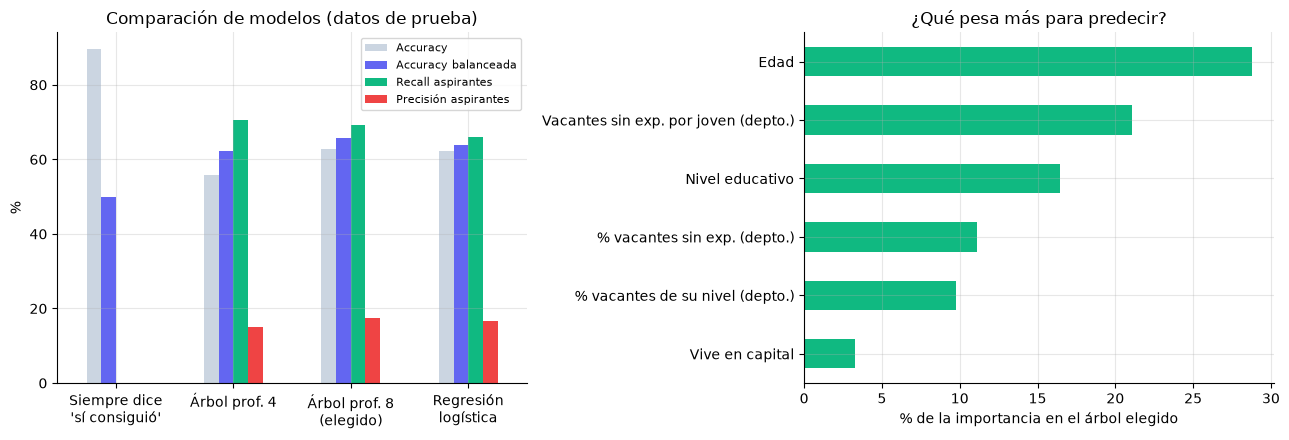

,accuracy_entrenamiento,accuracy_prueba,precision_aspirante,recall_aspirante,f1_aspirante,f1_insertado,accuracy_balanceada,auc
modelo,,,,,,,,
Siempre dice 'sí consiguió',0.896,0.896,0.000,0.000,0.000,0.945,0.500,0.500
Árbol balanceado max_depth=4,0.570,0.558,0.151,0.705,0.249,0.687,0.623,0.672
Árbol balanceado max_depth=8,0.643,0.629,0.175,0.692,0.279,0.750,0.657,0.710
Regresión logística balanceada,0.627,0.622,0.167,0.661,0.267,0.746,0.639,0.689


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
m = modelos[["accuracy_prueba", "accuracy_balanceada", "recall_aspirante", "precision_aspirante"]] * 100
m.index = ["Siempre dice\n'sí consiguió'", "Árbol prof. 4", "Árbol prof. 8\n(elegido)", "Regresión\nlogística"]
m.plot.bar(ax=ax[0], rot=0, color=["#cbd5e1", "#6366f1", "#10b981", "#ef4444"])
ax[0].set_ylabel("%")
ax[0].set_title("Comparación de modelos (datos de prueba)")
ax[0].legend(["Accuracy", "Accuracy balanceada", "Recall aspirantes", "Precisión aspirantes"], fontsize=8)

nombres = {"edad": "Edad", "log_vacantes_sin_exp_por_1000": "Vacantes sin exp. por joven (depto.)",
           "nivel_educativo_grupo": "Nivel educativo", "pct_vacantes_sin_experiencia": "% vacantes sin exp. (depto.)",
           "pct_vacantes_su_nivel": "% vacantes de su nivel (depto.)", "vive_en_capital": "Vive en capital"}
imp = importancia.head(6).rename(nombres).iloc[::-1] * 100
imp.plot.barh(ax=ax[1], color="#10b981")
ax[1].set_xlabel("% de la importancia en el árbol elegido")
ax[1].set_title("¿Qué pesa más para predecir?")
plt.tight_layout()
plt.show()
modelos.round(3)

Un modelo que siempre diga que el joven consiguió empleo acierta el 89,6 %, solo porque 9 de cada 10 lo consiguen. Por eso no nos fijamos en el accuracy sino en si el modelo encuentra a los aspirantes.

El mejor fue un árbol de decisión de profundidad 8 con clases balanceadas. Encuentra el 69 % de los aspirantes, pero de cada 100 que marca solo 17 lo son de verdad. Su AUC es 0,71, mejor que el azar (0,5) pero lejos de ser confiable.

También revisamos la fuga de datos: si dejábamos las semanas buscando o el ingreso, el modelo daba 99,8 %, porque esas variables solo existen para uno de los dos grupos. Por eso no se usan.

Lo que más pesa es la edad (los de 18 a 20 años son los que más se quedan sin empleo), cuántas vacantes sin experiencia hay por cada joven en el departamento y el nivel educativo, lo mismo que vimos en el EDA y en la segmentación.

Este modelo solo debería usarse para decidir a quién llamar primero en un programa de orientación, nunca para decidir quién recibe ayuda y quién no.

### Hallazgo 4. Para muchos, el primer empleo es un rebusque

Esto sale de la detección de anomalías con Isolation Forest del Checkpoint 2 (sección 3).

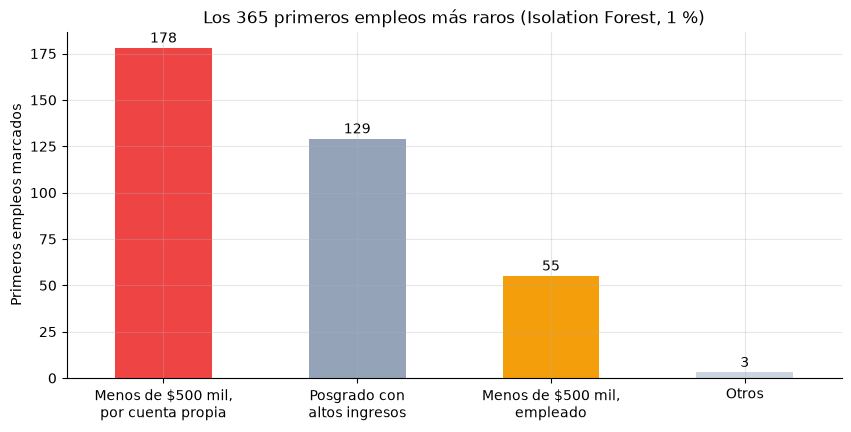

In [6]:
def tipo_anomalia(r):
    if r["ingreso_laboral_mensual"] < 500_000 and r["posicion_ocupacional"] == "Cuenta propia":
        return "Menos de $500 mil,\npor cuenta propia"
    if r["ingreso_laboral_mensual"] < 500_000:
        return "Menos de $500 mil,\nempleado"
    if r["nivel_educativo_grupo"] == "Posgrado":
        return "Posgrado con\naltos ingresos"
    return "Otros"

tipos = anomalias.apply(tipo_anomalia, axis=1).value_counts()
COLOR_TIPO = {"Menos de $500 mil,\npor cuenta propia": "#ef4444", "Menos de $500 mil,\nempleado": "#f59e0b",
              "Posgrado con\naltos ingresos": "#94a3b8", "Otros": "#cbd5e1"}
ax = tipos.plot.bar(rot=0, color=[COLOR_TIPO[t] for t in tipos.index])
ax.set_ylabel("Primeros empleos marcados")
ax.set_title(f"Los {len(anomalias)} primeros empleos más raros (Isolation Forest, 1 %)")
for i, v in enumerate(tipos):
    ax.text(i, v + 3, str(v), ha="center")
plt.show()

De los 365 primeros empleos que más se salen de lo normal (por la combinación de edad, estudios e ingreso), 233 pagan menos de $500.000 al mes, y la mayoría son trabajos por cuenta propia. Es decir, "conseguir empleo" no siempre significa tener un trabajo del que se pueda vivir, y el 91,9 % de inserción esconde muchos de estos casos. Los posgrados con ingresos altos no son un problema: salen como raros porque hay pocos jóvenes con posgrado.

### Recomendaciones

Juntando todo lo anterior:

1. **Qué formación recomendar:** técnica o tecnológica para el que necesita trabajar pronto, y universitaria completa para el que puede estudiar 5 años (hallazgo 1).
2. **Hacia dónde orientar:** a los departamentos del grupo A; en los grupos B y C, llevar los programas allá (hallazgo 2).
3. **A quién atender primero:** a los de 18 a 20 años en departamentos con pocas vacantes por joven. El modelo puede ayudar a ordenar la lista, pero la decisión la toma una persona (hallazgos 2 y 3).
4. **Cómo medir si un programa funciona:** no solo con el % que consiguió empleo, también con el % que tiene empleo formal y con el ingreso (hallazgo 4).

---
## 3. Documentación del proceso

Todo está en el repositorio https://github.com/samuelvelez1003/Busqueda-Empleo. Los notebooks se pueden correr en Google Colab (la primera celda clona el repositorio) o en Jupyter.

Así quedó cada unidad del curso:

| Unidad | Tema | Dónde está | Qué hicimos |
|---|---|---|---|
| 1 | Problema de negocio | `docs/Ficha_Proyecto_...pdf` y el README | La pregunta, la hipótesis y las fuentes |
| 2 | Adquisición de datos | `02_limpieza` y `03_adquisicion_cruce` (secciones 1 a 5) | Unir los 12 meses de la GEIH, armar la variable objetivo, leer el SPE, cruzar por código de departamento y el diccionario |
| 3 | Calidad y EDA | `01_exploracion` (práctica con datos simulados) y `03` (secciones 6 y 7) | Tipos de dato, atípicos, 5 gráficos y 5 hallazgos |
| 4 | Ingeniería de características | `03` (sección 8) y `preparacion.py` | 5 variables nuevas, codificación, escalado y la función `preparar_datos()` |
| 5 | Segmentación | `04_segmentacion_modelo_anomalias` (sección 1) | K-means, jerárquico y DBSCAN con los 33 departamentos |
| 6 | Modelo predictivo | `04` (sección 2) | Árbol de decisión y regresión logística, con revisión de fuga y sobreajuste |
| 7 | Técnica complementaria | `04` (sección 3) | Anomalías con Isolation Forest, 4 configuraciones |
| 8 | Producto final | `05_producto_final` y este informe | Juntar todo |

Para volver a correr todo: clonar el repositorio, instalar `pandas numpy matplotlib openpyxl scikit-learn scipy jupyter` y correr en orden `02_limpieza`, `03_adquisicion_cruce`, `04_segmentacion_modelo_anomalias` y `05_producto_final` desde la carpeta `notebooks/`.

Los datos originales del DANE y del SPE están en `data/raw/` sin modificar, y cada notebook guarda lo que produce en `data/processed/`. Todo lo aleatorio usa `random_state=42`, así que da lo mismo cada vez que se corre. El notebook 04 además imprime una "huella" de la matriz de datos para comprobar que es la misma del 03.

---
## 4. Limitaciones, riesgos y consideraciones éticas

### Decisiones que no se deberían tomar solo con este análisis

- Decidir quién entra o no a un programa usando el modelo. 4 de cada 5 alertas son falsas y se le escapan 3 de cada 10 aspirantes.
- Decir que estudiar "no sirve" porque los que menos estudiaron entran más rápido, cuando entran a peores trabajos.
- Quitar o recortar programas en un departamento por el grupo en que quedó. Los grupos son de 2025, no están tan separados (silueta de 0,38) y 4 departamentos cambian de grupo según el método.
- Sacar conclusiones de Amazonas, Guainía u otros departamentos con muy pocos encuestados.
- Hablar de causas. Todo lo que encontramos son asociaciones: la encuesta es una foto de cada mes y no sigue a la misma persona. No sabemos si la formación técnica *causa* el empleo formal o si los que la escogen ya tenían otras ventajas.

### Sesgos y huecos de los datos

- **"Sin experiencia" es una aproximación.** La GEIH no pregunta si es el primer empleo, así que usamos "ocupado con 12 meses o menos en su trabajo". Puede que algunos ya hubieran trabajado antes.
- **El nivel educativo incluye a los que todavía estudian.** El 47 % de los "universitarios" está estudiando. Nos dimos cuenta tarde, con las anomalías, y corregimos el hallazgo 1.
- **Los años no coinciden:** la GEIH es de 2025 y el SPE de 2023, porque es lo último publicado. La demanda pudo cambiar.
- **El SPE solo tiene las vacantes que se registran ahí.** Se queda por fuera la contratación informal o por conocidos, que es justo como entra la mayoría en el grupo C.
- **Faltan variables importantes** como el área de estudio, las prácticas, los contactos o a cuántas vacantes aplicó. Por eso el modelo no pasa de un AUC de 0,71.
- **El modelo no usa el factor de expansión**, así que aprende de la muestra y no de la población, y los departamentos pequeños pesan más de lo que deberían.
- **Hay 9 que consiguieron empleo por cada aspirante.** Si no se balancean las clases, cualquier métrica de acierto engaña.

### ¿Qué pasaría si alguien usara esto sin que una persona lo revise?

- Con el modelo, se podría dejar por fuera a un joven solo por su edad o por dónde vive, castigando justo a los más vulnerables, y con un modelo que se equivoca en la mayoría de sus alertas.
- Con la segmentación, decir que un departamento es de los que "cuesta entrar" podría desanimar la inversión allá, cuando debería ser al revés.
- Con las anomalías, usar la lista para decir que alguien mintió en la encuesta o para sacarlo de algo afectaría a los que ganan casi nada, que son los que más necesitan apoyo.
- Con la tasa de inserción sola, un programa podría verse exitoso aunque mande a los jóvenes al rebusque.

Por eso estos resultados sirven para orientar y priorizar, pero cualquier decisión sobre una persona o un territorio debería pasar por alguien que conozca el caso, y siempre hay que medir también la calidad del empleo y no solo si se consiguió.